# Classifier for fish Calls


In [127]:
import torch
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader
import torch.optim as optim
import torch.nn as nn
from torch.utils.data import random_split
import torch.nn.functional as F

import random

import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

### Loading the Fake Data

In [128]:
transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1), #ensures 1-channel
    transforms.ToTensor(), # changes pixels and shape
    transforms.Normalize(mean=[0.5], std=[0.5])
])

bad_dataset = datasets.ImageFolder(
    root="D:/POTENTIAL Fish sounds/random_snips",
    transform=transform
)

loader_bad = DataLoader(bad_dataset, batch_size=8, shuffle=True) #Bigger is better - probably?

In [129]:
print(bad_dataset.class_to_idx)

{'a': 0, 'b': 1, 'c': 2, 'd': 3, 'e': 4}


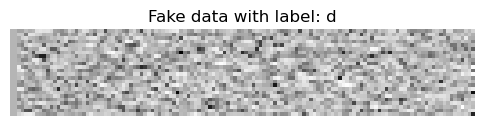

In [130]:
imgs, labels = next(iter(loader_bad))

img = imgs[0]
label_indx = labels[0].item()
img_np = img.squeeze().numpy()

plt.figure(figsize=(6,4))
plt.imshow(img_np, cmap='gray')
plt.title(f"Fake data with label: {bad_dataset.classes[label_indx]}")
plt.axis('off')
plt.show()

### Loading the Good Data: 

In [131]:
good_dataset = datasets.ImageFolder(
    root="D:/POTENTIAL Fish sounds/cnn_snips",
    transform=transform
)


train_size = int(0.8 * len(good_dataset))
val_size = len(good_dataset) - train_size

train_dataset, val_dataset = random_split(good_dataset, [train_size, val_size])

train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=8, shuffle=False)

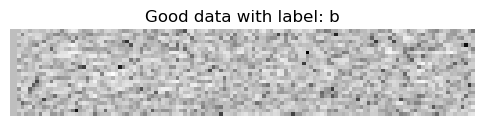

In [132]:
imgs, labels = next(iter(train_loader))

img = imgs[0]
label_indx = labels[0].item()
img_np = img.squeeze().numpy()

plt.figure(figsize=(6,4))
plt.imshow(img_np, cmap='gray')
plt.title(f"Good data with label: {good_dataset.classes[label_indx]}")
plt.axis('off')
plt.show()

### Perform Pretraining

In [133]:
from torchvision.models import mobilenet_v3_small
from torchvision.models import efficientnet_b0

In [134]:
class ConvEmbedding(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 64, 3, padding=1), nn.ReLU(), nn.AdaptiveAvgPool2d(1)
        )

    def forward(self, x):
        x = self.encoder(x)
        return x.view(x.size(0), -1)
def prototypical_loss(embeddings, labels, n_support):
    classes = torch.unique(labels)
    n_classes = len(classes)

    support_idx = []
    query_idx = []

    for c in classes:
        idx = torch.where(labels == c)[0]
        support_idx.append(idx[:n_support])
        query_idx.append(idx[n_support:])

    support_idx = torch.cat(support_idx)
    query_idx = torch.cat(query_idx)

    support = embeddings[support_idx]
    query = embeddings[query_idx]

    # compute prototypes
    prototypes = []
    for c in classes:
        idx = torch.where(labels[support_idx] == c)[0]
        prototypes.append(support[idx].mean(0))
    prototypes = torch.stack(prototypes)

    # compute distances
    dists = torch.cdist(query, prototypes)

    # compute loss
    log_p_y = F.log_softmax(-dists, dim=1)
    loss = -log_p_y[range(len(query)), labels[query_idx]].mean()

    _, preds = torch.min(dists, dim=1)
    acc = (preds == labels[query_idx]).float().mean()

    return loss, acc

def augment(x):
    # time masking
    t = random.randint(0, x.size(-1) - 16)
    x[:, :, :, t:t+16] = 0

    # freq masking
    f = random.randint(0, x.size(-2) - 4)
    x[:, :, f:f+4, :] = 0

    return x

def nt_xent_loss(z1, z2, temperature=0.1):
    z1 = F.normalize(z1, dim=1)
    z2 = F.normalize(z2, dim=1)

    logits = z1 @ z2.t() / temperature
    labels = torch.arange(z1.size(0)).to(z1.device)

    return F.cross_entropy(logits, labels)


def sample_episode(dataset, n_way=3, n_support=10, n_query=3):
    # unwrap Subset → get underlying dataset
    base = dataset.dataset if hasattr(dataset, "dataset") else dataset

    # get all class labels (only A/B/C now)
    all_classes = sorted(list(set([label for _, label in base.samples])))

    # pick n_way classes
    chosen_classes = random.sample(all_classes, n_way)

    support_imgs, support_labels = [], []
    query_imgs, query_labels = [], []

    class_map = {c: i for i, c in enumerate(chosen_classes)}

    for c in chosen_classes:
        idxs = [i for i in range(len(dataset)) if dataset[i][1] == c]
        random.shuffle(idxs)

        support = idxs[:n_support]
        query = idxs[n_support:n_support+n_query]

        for idx in support:
            img, _ = dataset[idx]
            support_imgs.append(img)
            support_labels.append(class_map[c])

        for idx in query:
            img, _ = dataset[idx]
            query_imgs.append(img)
            query_labels.append(class_map[c])

    imgs = torch.stack(support_imgs + query_imgs)
    labels = torch.tensor(support_labels + query_labels)

    return imgs, labels

In [135]:
# --- Pretrain ConvEmbedding using contrastive learning ---
model = ConvEmbedding().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

for epoch in range(50):
    total_loss = 0
    for imgs, _ in loader_bad:
        imgs = imgs.to(device)

        # two augmented views
        x1 = augment(imgs)
        x2 = augment(imgs)

        # embeddings
        z1 = model(x1)
        z2 = model(x2)

        # contrastive loss
        loss = nt_xent_loss(z1, z2, temperature=0.1)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(f"Epoch {epoch+1}/50  Contrastive Loss: {total_loss/len(loader_bad):.4f}")

# save pretrained encoder
torch.save(model.state_dict(), "conv_pretrained.pth")


Epoch 1/50  Contrastive Loss: 1.0228
Epoch 2/50  Contrastive Loss: 0.8365
Epoch 3/50  Contrastive Loss: 0.4831
Epoch 4/50  Contrastive Loss: 0.4417
Epoch 5/50  Contrastive Loss: 0.3630
Epoch 6/50  Contrastive Loss: 0.2997
Epoch 7/50  Contrastive Loss: 0.1649
Epoch 8/50  Contrastive Loss: 0.1759
Epoch 9/50  Contrastive Loss: 0.2063
Epoch 10/50  Contrastive Loss: 0.1334
Epoch 11/50  Contrastive Loss: 0.0869
Epoch 12/50  Contrastive Loss: 0.0684
Epoch 13/50  Contrastive Loss: 0.0558
Epoch 14/50  Contrastive Loss: 0.0621
Epoch 15/50  Contrastive Loss: 0.0545
Epoch 16/50  Contrastive Loss: 0.0455
Epoch 17/50  Contrastive Loss: 0.0716
Epoch 18/50  Contrastive Loss: 0.0586
Epoch 19/50  Contrastive Loss: 0.0645
Epoch 20/50  Contrastive Loss: 0.0622
Epoch 21/50  Contrastive Loss: 0.0554
Epoch 22/50  Contrastive Loss: 0.0456
Epoch 23/50  Contrastive Loss: 0.0410
Epoch 24/50  Contrastive Loss: 0.0403
Epoch 25/50  Contrastive Loss: 0.0439
Epoch 26/50  Contrastive Loss: 0.0398
Epoch 27/50  Contrast

### Actual Training: 

In [136]:
for episode in range(2000):
    imgs, labels = sample_episode(train_dataset, n_way=3, n_support=5, n_query=10)

    imgs = imgs.to(device)
    labels = labels.to(device)

    embeddings = model(imgs)
    loss, acc = prototypical_loss(embeddings, labels, n_support=5)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()


## Evaluation

In [137]:
import numpy as np
from sklearn.metrics import confusion_matrix
import seaborn as sns

Validation Acc: 0.3667


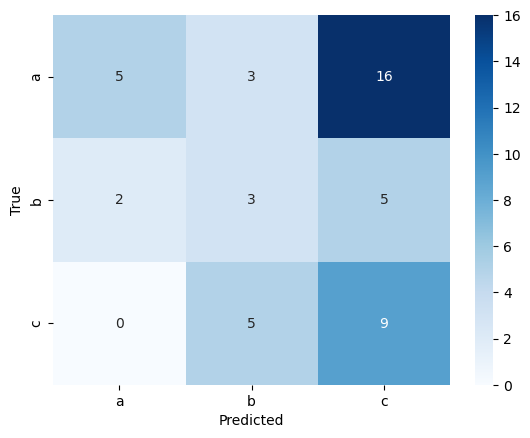

In [138]:
model.eval()
val_accs = []

for _ in range(50):  # 50 validation episodes
    imgs, labels = sample_episode(val_dataset, n_way=3, n_support=5, n_query=10)
    imgs, labels = imgs.to(device), labels.to(device)

    with torch.no_grad():
        embeddings = model(imgs)
        loss, acc = prototypical_loss(embeddings, labels, n_support=5)

    val_accs.append(acc.item())

print(f"Validation Acc: {np.mean(val_accs):.4f}")
model.train()

support_imgs, support_labels = sample_episode(train_dataset, n_way=3, n_support=10, n_query=0)
support_imgs = support_imgs.to(device)
support_labels = support_labels.to(device)

prototypes, proto_classes = compute_prototypes(model, support_imgs, support_labels)
prototypes = prototypes.to(device)
proto_classes = proto_classes.to(device)

all_preds = []
all_labels = []

for imgs, labels in val_loader:
    imgs = imgs.to(device)
    labels = labels.to(device)

    preds = predict_with_prototypes(model, prototypes, proto_classes, imgs)

    all_preds.extend(preds.cpu().numpy())
    all_labels.extend(labels.cpu().numpy())

cm = confusion_matrix(all_labels, all_preds)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["a","b","c"],
            yticklabels=["a","b","c"])
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()


In [139]:
for imgs, labels in val_loader:
    imgs = imgs.to(device)
    labels = labels.to(device)
    preds = predict_with_prototypes(final_model, prototypes, proto_classes, imgs)
    print("labels:", labels[:10].cpu().numpy())
    print("preds: ", preds[:10].cpu().numpy())
    break


labels: [2 2 0 1 0 0 0 0]
preds:  [1 1 1 1 1 1 1 1]
